In [51]:
import sys
print(sys.executable)

c:\Users\debna\ML-Projects\SMS-Spam-Detection\.venv\Scripts\python.exe


In [52]:
import sys
import numpy as np
import pandas as pd
import sklearn

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Environment configured successfully!")

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy: 2.4.6
Pandas: 3.1.1
Scikit-learn: 1.9.1
Environment configured successfully!


In [53]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nDataset folder contents:")
print(os.listdir("../dataset"))

Current working directory:
c:\Users\debna\ML-Projects\SMS-Spam-Detection\notebooks

Dataset folder contents:
['readme', 'SMSSpamCollection']


In [54]:
import os

path = "../dataset/SMSSpamCollection"

print("Exists:", os.path.exists(path))
print("Is file:", os.path.isfile(path))
print("Is folder:", os.path.isdir(path))

Exists: True
Is file: True
Is folder: False


In [55]:
import pandas as pd

df = pd.read_csv(
    "../dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [56]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5572, 2)

Column names:
Index(['label', 'message'], dtype='str')

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


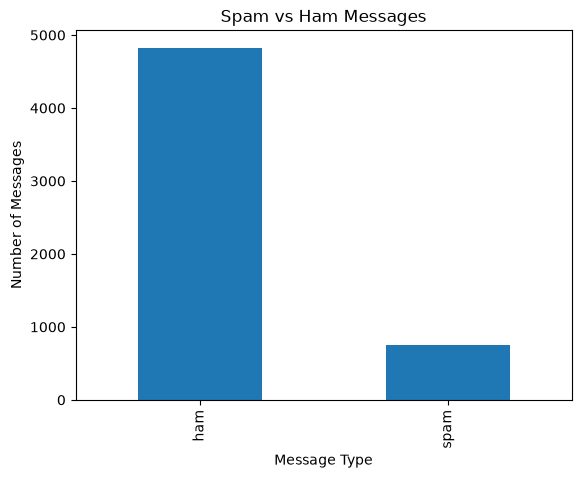

In [57]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(
    kind="bar",
    title="Spam vs Ham Messages"
)

plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

In [58]:
df.head(10)

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB


In [60]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 403


In [61]:
df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (5169, 2)


In [62]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [63]:
df = df.dropna(subset=["label", "message"])

In [64]:
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["label", "label_num"]].head())

  label  label_num
0   ham          0
1   ham          0
2  spam          1
3   ham          0
4   ham          0


In [65]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_message"] = df["message"].apply(clean_text)

df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [66]:
for i in range(5):
    print("Original:", df["message"].iloc[i])
    print("Cleaned:", df["clean_message"].iloc[i])
    print("-" * 50)

Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned: go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
--------------------------------------------------
Original: Ok lar... Joking wif u oni...
Cleaned: ok lar joking wif u oni
--------------------------------------------------
Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned: free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry questionstd txt ratetcs apply 08452810075over18s
--------------------------------------------------
Original: U dun say so early hor... U c already then say...
Cleaned: u dun say so early hor u c already then say
--------------------------------------------------
Original: Nah I don't think he goes to usf, he live

In [67]:
print("Final dataset shape:", df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Final dataset shape: (5169, 4)

Class distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

Missing values:
label            0
message          0
label_num        0
clean_message    0
dtype: int64


In [68]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

In [69]:
X = tfidf.fit_transform(df["clean_message"])

y = df["label_num"]

In [70]:
print("Feature matrix shape:", X.shape)

print("Number of features:", len(tfidf.get_feature_names_out()))

print("First 10 features:")
print(tfidf.get_feature_names_out()[:10])

Feature matrix shape: (5169, 5000)
Number of features: 5000
First 10 features:
['020603' '020603 this' '0800' '08000839402' '08000839402 or'
 '08000930705' '08000930705 for' '08001950382' '08001950382 or' '0870']


In [71]:
print("Original message:")
print(df["clean_message"].iloc[0])

print("\nNumerical representation:")
print(X[0].toarray())

Original message:
go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat

Numerical representation:
[[0. 0. 0. ... 0. 0. 0.]]


In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_message"],
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [73]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

In [74]:
X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4135,)
Testing data: (1034,)


In [75]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ("classifier", MultinomialNB())
])

In [76]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [77]:
y_pred = model.predict(X_test)

print("Actual labels:", y_test.iloc[:10].tolist())
print("Predicted labels:", y_pred[:10].tolist())

Actual labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Predicted labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [78]:
messages = [
    "Congratulations! You won a free prize. Claim now!",
    "Hey, are we meeting tomorrow?",
    "URGENT! You have won 10000 cash. Call now!",
    "Please bring my book when you come."
]

predictions = model.predict(messages)

for message, prediction in zip(messages, predictions):
    result = "SPAM" if prediction == 1 else "HAM"

    print("Message:", message)
    print("Prediction:", result)
    print("-" * 60)

Message: Congratulations! You won a free prize. Claim now!
Prediction: SPAM
------------------------------------------------------------
Message: Hey, are we meeting tomorrow?
Prediction: HAM
------------------------------------------------------------
Message: URGENT! You have won 10000 cash. Call now!
Prediction: SPAM
------------------------------------------------------------
Message: Please bring my book when you come.
Prediction: HAM
------------------------------------------------------------


In [79]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [80]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 96.62 %


In [81]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.73      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



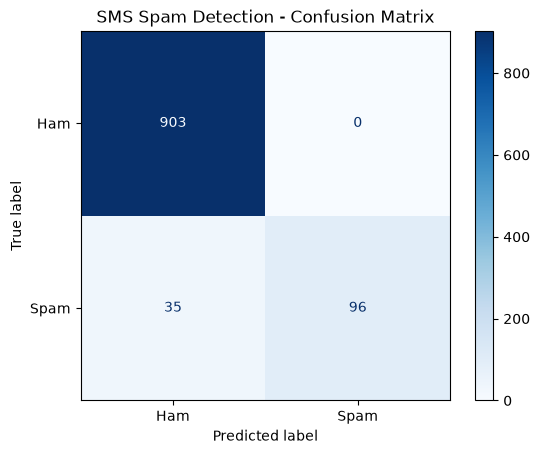

In [82]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

In [83]:
import joblib

joblib.dump(model, "../models/spam_detection_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [84]:
loaded_model = joblib.load("../models/spam_detection_model.pkl")

test_message = [
    "Congratulations! You have won a free prize. Claim now!"
]

prediction = loaded_model.predict(test_message)

print("SPAM" if prediction[0] == 1 else "HAM")

SPAM


In [85]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

In [86]:
models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "SVM": LinearSVC(
        class_weight="balanced"
    )
}

In [87]:
results = []

trained_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

    trained_models[name] = pipeline

In [88]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
2                  SVM    0.9797     0.9365  0.9008    0.9183
1  Logistic Regression    0.9758     0.9077  0.9008    0.9042
0          Naive Bayes    0.9662     1.0000  0.7328    0.8458


In [89]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

import joblib

joblib.dump(
    best_model,
    "../models/best_spam_detection_model.pkl"
)

print("Best model:", best_model_name)
print("Best model saved successfully!")

Best model: SVM
Best model saved successfully!


Confusion Matrix:
[[895   8]
 [ 13 118]]


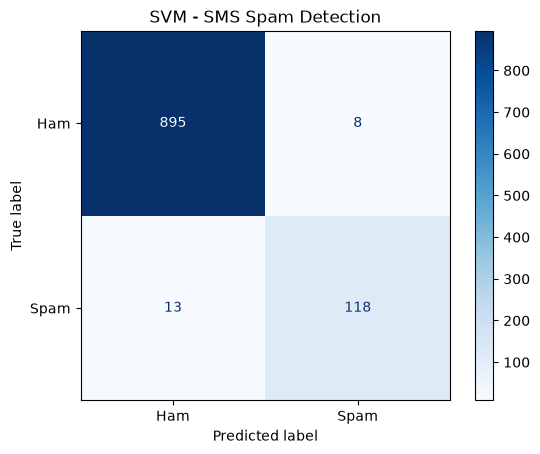

In [90]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model = trained_models["SVM"]

y_pred_svm = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_svm)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
).plot(cmap="Blues")

plt.title("SVM - SMS Spam Detection")
plt.show()

In [91]:
error_analysis = df.loc[
    X_test.index,
    ["message", "label"]
].copy()

error_analysis["prediction"] = y_pred_svm

error_analysis["predicted_label"] = (
    error_analysis["prediction"]
    .map({0: "ham", 1: "spam"})
)

errors = error_analysis[
    error_analysis["label"] != error_analysis["predicted_label"]
]

print("Total incorrect predictions:", len(errors))

errors.head(20)

Total incorrect predictions: 21


,message,label,prediction,predicted_label
1262,Your daily text from me – a favour this time,ham,1,spam
5137,Want explicit SEX in 30 secs? Ring 02073162414...,spam,0,ham
521,You will recieve your tone within the next 24h...,spam,0,ham
4622,I'm vivek:)i got call from your number.,ham,1,spam
5139,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...,spam,0,ham
487,Are you free now?can i call now?,ham,1,spam
3599,Please protect yourself from e-threats. SIB ne...,ham,1,spam
1423,Hi its LUCY Hubby at meetins all day Fri & I w...,spam,0,ham
3949,Missed call alert. These numbers called but le...,spam,0,ham
4806,K k:) sms chat with me.,ham,1,spam


In [92]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

In [93]:
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LinearSVC())
])

In [94]:
param_grid = {
    "tfidf__max_features": [3000, 5000, 7000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

In [95]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [96]:
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'tfidf__max_features': 7000, 'tfidf__ngram_range': (1, 2)}

Best Cross-Validation F1 Score:
0.9348


In [97]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

tuned_model = grid_search.best_estimator_

y_pred_tuned = tuned_model.predict(X_test)

print("Tuned SVM Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Ham", "Spam"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned SVM Accuracy: 98.07 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       903
        Spam       0.94      0.91      0.92       131

    accuracy                           0.98      1034
   macro avg       0.96      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034


Confusion Matrix:
[[895   8]
 [ 12 119]]


In [98]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "final_spam_detection_model.pkl"

joblib.dump(tuned_model, model_path)

print("Final model saved:", model_path)

Final model saved: ..\models\final_spam_detection_model.pkl


In [99]:
loaded_model = joblib.load(model_path)

test_messages = [
    "Congratulations! You won a free iPhone. Claim your prize now!",
    "Hey, are you coming to college tomorrow?",
    "URGENT! Your account has been selected for a cash reward.",
    "Please call me when you reach home."
]

predictions = loaded_model.predict(test_messages)

for message, prediction in zip(test_messages, predictions):
    label = "SPAM" if prediction == 1 else "HAM"

    print(f"Message: {message}")
    print(f"Prediction: {label}")
    print("-" * 50)

Message: Congratulations! You won a free iPhone. Claim your prize now!
Prediction: SPAM
--------------------------------------------------
Message: Hey, are you coming to college tomorrow?
Prediction: HAM
--------------------------------------------------
Message: URGENT! Your account has been selected for a cash reward.
Prediction: SPAM
--------------------------------------------------
Message: Please call me when you reach home.
Prediction: HAM
--------------------------------------------------
